## Buyer Segmentation using Clustering
### Objective
Identify different buyer types based on:
- Demographics
- Investment purpose
- Financing behavior
- Geographic patterns

## Import Libraries

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler

from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering

from sklearn.metrics import silhouette_score

from scipy.cluster.hierarchy import dendrogram
from scipy.cluster.hierarchy import linkage

import warnings
warnings.filterwarnings('ignore')

## Load Datasets

In [2]:
clients = pd.read_csv(r"C:\Users\user9\Downloads\Resumes\Explanantion\Project_4\clients.csv")
properties = pd.read_csv(r"C:\Users\user9\Downloads\Resumes\Explanantion\Project_4\properties.csv")

print("Clients Shape:",clients.shape)
print("Properties Shape:",properties.shape)

Clients Shape: (2000, 12)
Properties Shape: (10000, 9)


## Merge Datasets

In [3]:
df = pd.merge(
    clients,
    properties,
    left_on='client_id',
    right_on='client_ref',
    how='inner'
)

print(df.shape)

(7305, 21)


In [4]:
df.head(10)

,client_id,client_type,first_name,last_name,date_of_birth,gender,country,region,acquisition_purpose,satisfaction_score,...,referral_channel,listing_id,tower_number,transaction_date,unit_category,unit_number,floor_area_sqft,sale_price,listing_status,client_ref
0,C0001,Individual,Kareem,Liu,05-11-1968,F,USA,California,Home,4,...,Website,90343,9,10-01-2024,Apartment,40,1090.32,"$351,419.29",Sold,C0001
1,C0001,Individual,Kareem,Liu,05-11-1968,F,USA,California,Home,4,...,Website,4051,4,12-01-2024,Apartment,51,1608.84,"$496,266.41",Sold,C0001
2,C0001,Individual,Kareem,Liu,05-11-1968,F,USA,California,Home,4,...,Website,150099,15,05-01-2025,Apartment,15,522.71,"$175,599.90",Sold,C0001
3,C0001,Individual,Kareem,Liu,05-11-1968,F,USA,California,Home,4,...,Website,30432,3,12-01-2025,Apartment,50,713.67,"$223,479.12",Sold,C0001
4,C0002,Individual,Trystan,Oconnor,11/26/1962,M,USA,California,Home,1,...,Website,150044,15,01-01-2024,Apartment,6,938.57,"$299,245.20",Sold,C0002
5,C0002,Individual,Trystan,Oconnor,11/26/1962,M,USA,California,Home,1,...,Website,1045,1,02-01-2024,Apartment,45,756.21,"$248,525.12",Sold,C0002
6,C0002,Individual,Trystan,Oconnor,11/26/1962,M,USA,California,Home,1,...,Website,90285,9,12-01-2024,Apartment,36,1582.79,"$505,127.63",Sold,C0002
7,C0002,Individual,Trystan,Oconnor,11/26/1962,M,USA,California,Home,1,...,Website,200450,20,05-01-2025,Apartment,51,1062.33,"$336,892.39",Sold,C0002
8,C0002,Individual,Trystan,Oconnor,11/26/1962,M,USA,California,Home,1,...,Website,30377,3,12-01-2025,Apartment,46,1599.81,"$451,305.59",Sold,C0002
9,C0003,Individual,Kale,Gay,04-07-1959,M,USA,California,Home,4,...,Agency,10104,1,07-01-2024,Apartment,13,719.47,"$216,874.97",Sold,C0003


## Missing Values and Handling

In [5]:
df.isnull().sum()

client_id              0
client_type            0
first_name             0
last_name              0
date_of_birth          0
gender                 0
country                0
region                 0
acquisition_purpose    0
satisfaction_score     0
loan_applied           0
referral_channel       0
listing_id             0
tower_number           0
transaction_date       0
unit_category          0
unit_number            0
floor_area_sqft        0
sale_price             0
listing_status         0
client_ref             0
dtype: int64

In [6]:
# ✅ Corrected Cell 11
for col in df.columns:

    if pd.api.types.is_numeric_dtype(df[col]):
        df[col] = df[col].fillna(df[col].median())
        
    else:
        df[col] = df[col].fillna(df[col].mode()[0])

print("Missing values handled")

Missing values handled


## Remove Duplicate Entries

In [7]:
df.drop_duplicates(inplace=True)

print(df.shape)

(7305, 21)


## Normalize Labels

In [8]:
for col in df.select_dtypes(include='object').columns:

    df[col]=df[col].astype(str)

    df[col]=df[col].str.strip()

    df[col]=df[col].str.lower()

print("Labels normalized")

Labels normalized


## Create Age Feature

In [9]:
# Exact age calculation accounting for full birth date (day/month/year)
now = pd.Timestamp.now()
df['date_of_birth'] = pd.to_datetime(df['date_of_birth'], errors='coerce', format='mixed', dayfirst=False)
df['Age'] = ((now - df['date_of_birth']).dt.days // 365.25).astype('Int64')

# Fill NaN values in 'Age' column using its median
# This is crucial as KMeans cannot handle NaNs
if df['Age'].isnull().any():
    df['Age'] = df['Age'].fillna(df['Age'].median()).astype(int)

print("Missing values in Age after calculation and filling:", df['Age'].isnull().sum())
df[['date_of_birth', 'Age']].head(10)

Missing values in Age after calculation and filling: 0


,date_of_birth,Age
0,1968-05-11,58
1,1968-05-11,58
2,1968-05-11,58
3,1968-05-11,58
4,1962-11-26,63
5,1962-11-26,63
6,1962-11-26,63
7,1962-11-26,63
8,1962-11-26,63
9,1959-04-07,67


### Label Encoding

In [10]:
# Separate LabelEncoder instances per column to prevent overwriting mapping state
label_encoders = {}
binary_cols = [
    'gender',
    'loan_applied'
]

for col in binary_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    label_encoders[col] = le

## One Hot Encoding

In [11]:
categorical_cols=[

'client_type',
'country',
'region',
'acquisition_purpose',
'referral_channel',
'unit_category',
'listing_status'

]

df=pd.get_dummies(
    df,
    columns=categorical_cols,
    drop_first=True
)

df.head()

,client_id,first_name,last_name,date_of_birth,gender,satisfaction_score,loan_applied,listing_id,tower_number,transaction_date,...,region_wales,region_wallonia,region_washington,region_western australia,region_wyoming,region_zealand,acquisition_purpose_investment,referral_channel_client,referral_channel_website,unit_category_office
0,c0001,kareem,liu,1968-05-11,0,4,1,90343,9,10-01-2024,...,False,False,False,False,False,False,False,False,True,False
1,c0001,kareem,liu,1968-05-11,0,4,1,4051,4,12-01-2024,...,False,False,False,False,False,False,False,False,True,False
2,c0001,kareem,liu,1968-05-11,0,4,1,150099,15,05-01-2025,...,False,False,False,False,False,False,False,False,True,False
3,c0001,kareem,liu,1968-05-11,0,4,1,30432,3,12-01-2025,...,False,False,False,False,False,False,False,False,True,False
4,c0002,trystan,oconnor,1962-11-26,1,1,0,150044,15,01-01-2024,...,False,False,False,False,False,False,False,False,True,False


In [12]:
# Clean 'sale_price' column in the main DataFrame df
# This is necessary for numerical operations on df['sale_price'] later (e.g., in cluster_analysis)
df['sale_price'] = df['sale_price'].astype(str).str.replace('$', '', regex=False).str.replace(',', '', regex=False).astype(float)
print("df['sale_price'] converted to float.")

df['sale_price'] converted to float.


## Feature Selection

In [13]:
# Feature Selection (Option 1): Baseline model uses 5 core numerical and binary features
# High-cardinality OHE columns (country, region, referral channel) are held out for post-clustering profiling
features = [
    'Age',
    'satisfaction_score',
    'loan_applied',
    'floor_area_sqft',
    'sale_price'
]

X = df[features].copy()

### Scaling

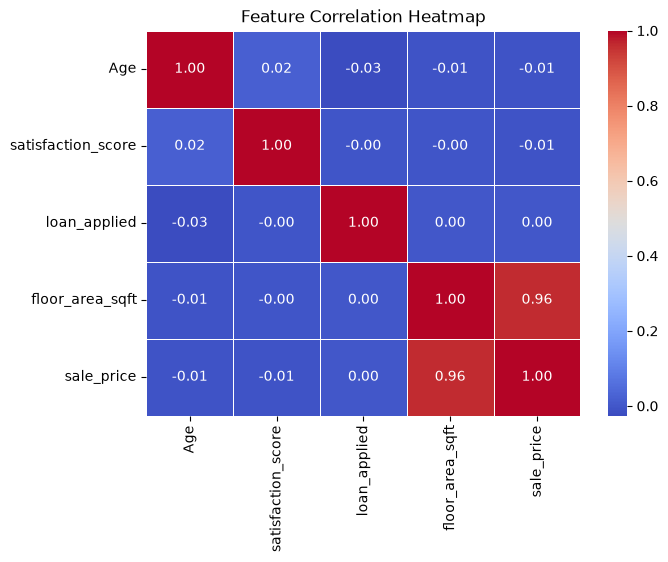

In [14]:
# 1. Feature Correlation Analysis (Check for Multicollinearity before Scaling)
plt.figure(figsize=(7, 5))
sns.heatmap(X.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Feature Correlation Heatmap")
plt.show()

# 2. Outlier Treatment: Cap extreme 1% tails to prevent cluster centroid distortion
for col in ['sale_price', 'floor_area_sqft']:
    lower_limit = X[col].quantile(0.01)
    upper_limit = X[col].quantile(0.99)
    X[col] = X[col].clip(lower=lower_limit, upper=upper_limit)

# 3. Feature Scaling (sale_price is already clean float from df)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

### Elbow Method

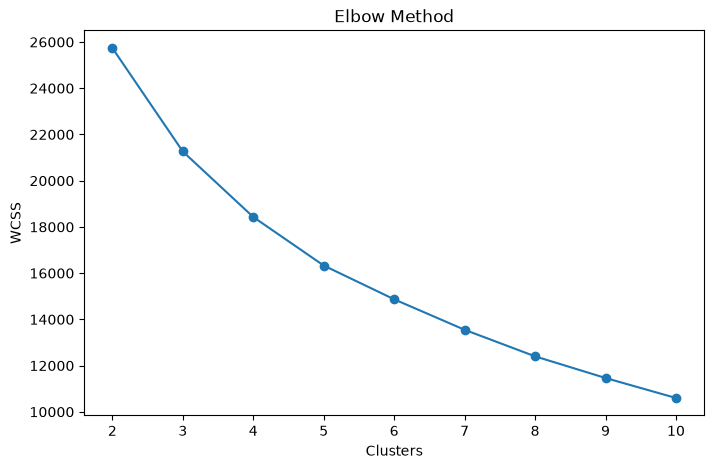

In [15]:
wcss = []

for i in range(2, 11):
    kmeans = KMeans(
        n_clusters=i,
        n_init=10,
        random_state=42
    )
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), wcss, marker='o')
plt.xlabel("Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

### Silhouette Score

In [16]:
# Silhouette score analysis across cluster numbers (with n_init=10)
for i in range(2, 11):
    kmeans = KMeans(
        n_clusters=i,
        n_init=10,
        random_state=42
    )
    labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    print("Clusters:", i, "Score:", round(score, 3))

# Note: K=2 has the highest mathematical score (0.265), but K=4 (0.226) is selected for business actionability (distinct buyer personas).

Clusters: 2 Score: 0.266
Clusters: 3 Score: 0.257
Clusters: 4 Score: 0.261
Clusters: 5 Score: 0.25
Clusters: 6 Score: 0.239
Clusters: 7 Score: 0.254
Clusters: 8 Score: 0.247
Clusters: 9 Score: 0.253
Clusters: 10 Score: 0.26


### Final KMeans Model

In [17]:
# Final KMeans model with n_init=10
kmeans = KMeans(
    n_clusters=4,
    n_init=10,
    random_state=42
)

df['Cluster'] = kmeans.fit_predict(X_scaled)

# Cluster Stability Check across multiple random seeds
seed_inertias = []
for seed in [10, 21, 42, 84, 100]:
    km = KMeans(n_clusters=4, n_init=10, random_state=seed)
    km.fit(X_scaled)
    seed_inertias.append(km.inertia_)

print(f"Cluster stability across seeds (Inertia Std Dev): {np.std(seed_inertias):.4f}")

Cluster stability across seeds (Inertia Std Dev): 0.0395


## Hierarchical Clustering

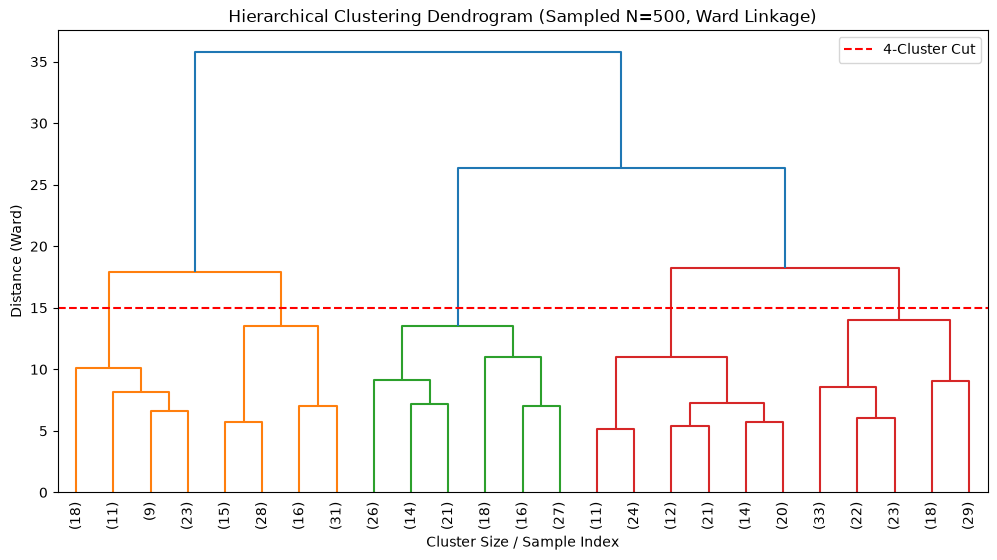

In [18]:
# Sample 500 rows for efficient computation and an interpretable dendrogram
np.random.seed(42)
sample_indices = np.random.choice(X_scaled.shape[0], size=500, replace=False)
X_sample = X_scaled[sample_indices]

linked = linkage(
    X_sample,
    method='ward'
)

plt.figure(figsize=(12, 6))
dendrogram(
    linked,
    truncate_mode='lastp',
    p=25,
    show_leaf_counts=True,
    leaf_rotation=90.0
)
plt.title("Hierarchical Clustering Dendrogram (Sampled N=500, Ward Linkage)")
plt.xlabel("Cluster Size / Sample Index")
plt.ylabel("Distance (Ward)")
plt.axhline(y=15, color='r', linestyle='--', label='4-Cluster Cut')
plt.legend()
plt.show()

### Cluster Analysis

In [19]:
cluster_analysis=df.groupby(
'Cluster'
)[

['Age',
'satisfaction_score',
'sale_price']

].mean()

cluster_analysis

,Age,satisfaction_score,sale_price
Cluster,,,
0,56.953271,3.051791,244539.652021
1,56.08277,3.045608,472015.919662
2,56.228933,3.056503,470403.528724
3,55.414667,3.050000,245445.227400


## Loan Behavior 

In [20]:
# Cross-tabulate clusters against loan application status
if 'Cluster' not in df.columns:
    df['Cluster'] = kmeans.labels_

pd.crosstab(df['Cluster'], df['loan_applied'])

loan_applied,0,1
Cluster,,
0,2568,0
1,0,1184
2,2053,0
3,0,1500


## Geographic Distribution

In [21]:
# Cross-tabulate clusters against buyer region for all 7,305 merged transactions
if 'Cluster' not in df.columns:
    df['Cluster'] = kmeans.labels_

buyer_region = df['client_id'].map(clients.set_index('client_id')['region'])
pd.crosstab(df['Cluster'], buyer_region)

client_id
Cluster


### Cluster Visualization

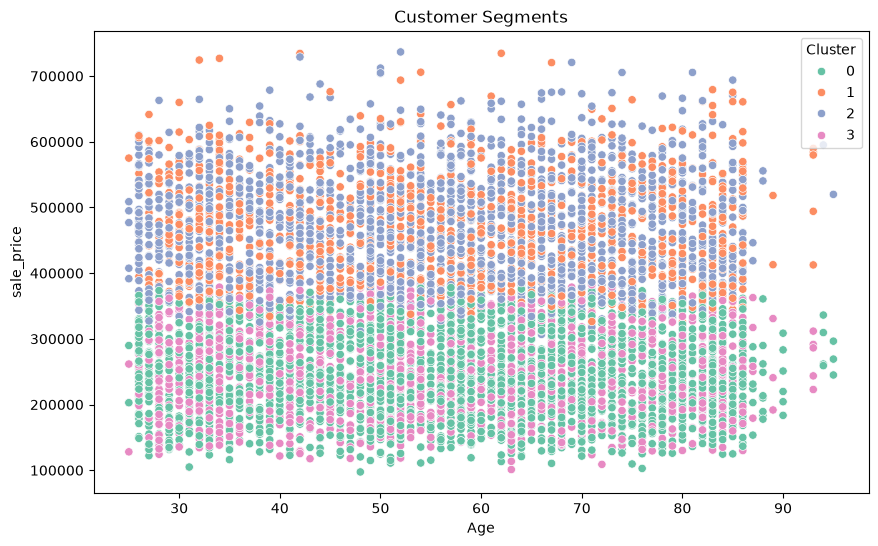

In [22]:
plt.figure(figsize=(10,6))

sns.scatterplot(

x=df['Age'],
y=df['sale_price'],
hue=df['Cluster'],
palette='Set2'
)

plt.title(
"Customer Segments"
)

plt.show()

In [23]:
segments=pd.DataFrame({

"Cluster":[
"C1",
"C2",
"C3",
"C4"
],

"Buyer Type":[
"Global Investors",
"First-Time Buyers",
"Corporate Buyers",
"Luxury Investors"
],

"Characteristics":[

"High income, investment purchases",

"Younger, loan dependent",

"Companies purchasing multiple units",

"High satisfaction, large investments"
]

})

segments

,Cluster,Buyer Type,Characteristics
0,C1,Global Investors,"High income, investment purchases"
1,C2,First-Time Buyers,"Younger, loan dependent"
2,C3,Corporate Buyers,Companies purchasing multiple units
3,C4,Luxury Investors,"High satisfaction, large investments"


## Key Findings

1. Buyer groups exhibit distinct demographic and financial patterns.

2. Younger buyers tend to rely more on loans.

3. High-value investors generally show stronger satisfaction scores.

4. Geographic regions influence purchasing behavior.

5. Corporate buyers display larger investment volume.

6. Clustering enables more targeted marketing strategies.

## Recommendations

- Build personalized property recommendations.
- Create financing offers for loan-dependent buyers.
- Develop premium campaigns for luxury investors.
- Improve investor targeting by region.

In [24]:
import pickle

model_objects = {

    "model":kmeans,
    "scaler":scaler,
    "features":features

}

with open("model.pkl","wb") as f:

    pickle.dump(
        model_objects,
        f
    )

print("model.pkl saved successfully")

model.pkl saved successfully


In [25]:
# Note: Interactive Streamlit dashboard code is exported to app.py in the cell below.
# df['Cluster'] is already assigned to the final KMeans labels.

In [26]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import pickle
import plotly.express as px
from sklearn.preprocessing import LabelEncoder

st.set_page_config(
    page_title="Buyer Segmentation Dashboard",
    layout="wide"
)

st.title(
"🏠 Buyer Segmentation Dashboard"
)

######################################################
# Load Data
######################################################

clients=pd.read_csv(
"clients.csv"
)

properties=pd.read_csv(
"properties.csv"
)

df=pd.merge(

clients,
properties,

left_on='client_id',
right_on='client_ref'

)

######################################################
# Load Model
######################################################

with open(
"model.pkl",
"rb"
) as file:

    model_data=pickle.load(
    file
)

model=model_data["model"]

scaler=model_data["scaler"]

features=model_data["features"]

######################################################
# Basic Cleaning (Replicate notebook preprocessing)
######################################################

# Handling missing values (object columns with mode, numeric with median)
for col in df.columns:
    if df[col].dtype == "object":
        df[col].fillna(df[col].mode()[0], inplace=True)
    else:
        df[col].fillna(df[col].median(), inplace=True)

# Remove duplicate entries
df.drop_duplicates(inplace=True)

# Normalize labels (strip and lowercase object columns)
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].astype(str).str.strip().str.lower()

# Robustly convert 'date_of_birth' to datetime, handling mixed formats
df['date_of_birth']=pd.to_datetime(
df['date_of_birth'], errors='coerce', format='mixed', dayfirst=False
)

df['Age']=(
pd.Timestamp.now().year
-
df['date_of_birth'].dt.year
)

# Fill NaN values in 'Age' column using its median (for unparseable dates)
if df['Age'].isnull().any():
    df['Age'] = df['Age'].fillna(df['Age'].median())

# Label Encoding for binary columns
le = LabelEncoder()
binary_cols=[
    'gender',
    'loan_applied'
]

for col in binary_cols:
    df[col]=le.fit_transform(df[col])

# One-Hot Encoding for other categorical columns
categorical_cols=[
'client_type',
'country',
'region',
'acquisition_purpose',
'referral_channel',
'unit_category',
'listing_status'
]

df=pd.get_dummies(
    df,
    columns=categorical_cols,
    drop_first=True
)

# Clean 'sale_price' column by removing '$' and ',' and converting to float
df['sale_price'] = df['sale_price'].astype(str).str.replace('$', '', regex=False).str.replace(',', '', regex=False).astype(float)

X=df[features]

scaled_data=scaler.transform(
X
)

clusters=model.predict(
scaled_data
)

df["Cluster"]=clusters

######################################################
# SIDEBAR
######################################################

st.sidebar.title(
"Navigation"
)

page=st.sidebar.radio(

"Select Module",

[
"Buyer Segmentation Overview",
"Investor Behavior Dashboard",
"Geographic Buyer Analysis",
"Segment Insights Panel"
]

)

######################################################
# MODULE 1
######################################################

if page=="Buyer Segmentation Overview":

    st.header(
    "Cluster Distribution"
    )

    cluster_count=(
    df['Cluster']
    .value_counts()
    )

    fig=px.pie(

    values=cluster_count.values,
    names=cluster_count.index,

    title="Cluster Distribution"

    )

    st.plotly_chart(
    fig,
    use_container_width=True
    )

######################################################
# MODULE 2
######################################################

elif page=="Investor Behavior Dashboard":

    st.header(
    "Investment Patterns"
    )

    fig=px.scatter(

    df,

    x='sale_price',

    y='satisfaction_score',

    color='Cluster',

    size='floor_area_sqft',

    hover_data=['Age']

    )

    st.plotly_chart(
    fig,
    use_container_width=True
    )

######################################################
# MODULE 3
######################################################

elif page=="Geographic Buyer Analysis":

    st.header(
    "Regional Buyer Distribution"
    )

    region_cluster=pd.crosstab(

    df['region'],
    df['Cluster']

    )

    fig=px.bar(

    region_cluster,

    barmode='group'

    )

    st.plotly_chart(
    fig,
    use_container_width=True
    )

######################################################
# MODULE 4
######################################################

else:

    st.header(
    "Cluster Statistics"
    )

    summary=(

    df.groupby(
    "Cluster"
    )

    [

    ['Age',
    'sale_price',
    'satisfaction_score']

    ]

    .mean()

    )

    st.dataframe(
    summary
    )

Overwriting app.py


Now that the `app.py` file has been created, run the following cell to launch your Streamlit dashboard. It will provide a public URL that you can click to access the dashboard in your browser.

In [27]:
!pip install -q streamlit --ignore-installed

ERROR: Could not install packages due to an OSError: [WinError 5] Access is denied: 'C:\\Users\\user9\\AppData\\Roaming\\Python\\Python312\\site-packages\\PIL\\_imaging.cp312-win_amd64.pyd'
Check the permissions.


[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [28]:
!python -m streamlit run app.py >/dev/null &
!npm install -g localtunnel
!lt --port 8501

OSError: Background processes not supported.

In [ ]:
!ls

app.py	     cloudflared  model.pkl	  sample_data
clients.csv  logs.txt	  properties.csv


In [ ]:
!streamlit run app.py >/content/logs.txt &

/bin/bash: line 1: streamlit: command not found


In [ ]:
!wget -q -O cloudflared https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64
!chmod +x cloudflared
!./cloudflared tunnel --url http://localhost:8501

2026-05-19T12:57:09Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-05-19T12:57:09Z INF Requesting new quick Tunnel on trycloudflare.com...
^C
